In [1]:
import pandas as pd

orders = pd.read_csv("../data/raw/olist_orders_dataset.csv")
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [2]:
import pandas as pd

RAW = "../data/raw/"
date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
orders = pd.read_csv(RAW + "olist_orders_dataset.csv", parse_dates=date_cols)
customers = pd.read_csv(RAW + "olist_customers_dataset.csv")
reviews = pd.read_csv(RAW + "olist_order_reviews_dataset.csv")
products = pd.read_csv(RAW + "olist_products_dataset.csv")
print(orders.shape, customers.shape, reviews.shape, products.shape)

(99441, 8) (99441, 5) (99224, 7) (32951, 9)


In [3]:
orders.order_status.value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [4]:
delivered = orders[
    (orders.order_status == "delivered") & orders.order_delivered_customer_date.notna()
].copy()
delivered["is_late"] = (
    delivered.order_delivered_customer_date > delivered.order_estimated_delivery_date
)
print(len(delivered), "delivered orders")
print("late rate:", round(delivered.is_late.mean(), 3))

96470 delivered orders
late rate: 0.081


In [5]:
orders.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

**Finding:** About 97% of orders are delivered. The late rate is about 8%, so late orders are rare and accuracy alone would be a misleading measure. And 8 delivered orders have no delivery date and are excluded.

In [6]:
d = delivered.merge(customers[["customer_id", "customer_state"]], on="customer_id")
print(d.shape)

(96470, 10)


In [15]:
by_state = d.groupby("customer_state").is_late.agg(["mean", "count"])
by_state.sort_values("mean", ascending=False).head(10)

,mean,count
customer_state,,
AL,0.239295,397
MA,0.196653,717
PI,0.159664,476
CE,0.153245,1279
SE,0.152239,335
BA,0.140356,3256
RJ,0.134737,12350
TO,0.127737,274
PA,0.123679,946


<Axes: title={'center': 'Late rate by month'}, xlabel='month'>

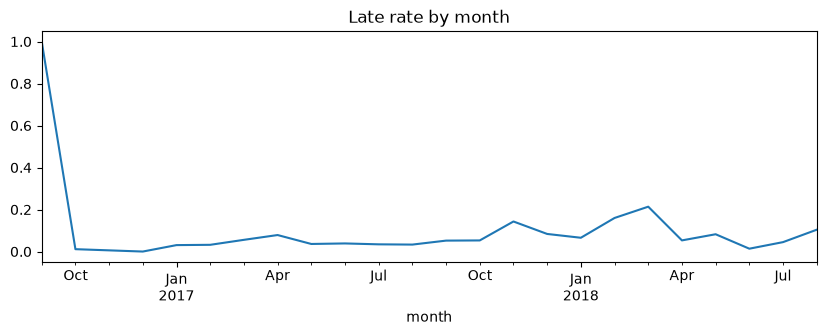

In [8]:
d["month"] = d.order_purchase_timestamp.dt.to_period("M")
monthly = d.groupby("month").is_late.mean()
monthly.plot(figsize=(10, 3), title="Late rate by month")

In [9]:
d["promised_days"] = (
    d.order_estimated_delivery_date - d.order_purchase_timestamp
).dt.days
d.groupby(pd.cut(d.promised_days, [0, 7, 14, 21, 30, 60, 200])).is_late.mean()

promised_days
(0, 7]       0.245419
(7, 14]      0.061095
(14, 21]     0.092573
(21, 30]     0.083294
(30, 60]     0.052375
(60, 200]    0.032864
Name: is_late, dtype: float64

**Finding:** Late rates differ a lot by state: the worst states are around 23%, while Rondônia (RO) is around 2.88% late (the lowest). Distance from sellers is probably a factor. And 2018 March had the worst late delivary.